# LoRA fine-tuning for medical QA: GPT-2 and TinyLlama


## Environment Setup

This cell installs the required libraries and imports the dependencies used throughout the project for model training, parameter-efficient fine-tuning, evaluation, and visualization.

In [1]:
# Installing required libraries for model training, evaluation, and visualization
!pip install -q transformers peft datasets accelerate sentence-transformers seaborn

import torch
import pandas as pd
import numpy as np
import time
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    TrainingArguments,
    Trainer,
    set_seed
)
from peft import LoraConfig, get_peft_model, TaskType
from sentence_transformers import SentenceTransformer, util


# Disabling warnings to keep output readable
warnings.filterwarnings('ignore')

from pathlib import Path
from importlib.metadata import version
import json

SEED = 42
CSV_PATH = 'disease_symptoms.csv'
RESULTS_DIR = Path('results')
RESULTS_DIR.mkdir(exist_ok=True)
# Record the actual installed versions rather than guessing the original environment.
environment = {name: version(name) for name in
               ['torch', 'transformers', 'peft', 'datasets', 'accelerate',
                'sentence-transformers', 'pandas', 'numpy', 'matplotlib', 'seaborn']}
(RESULTS_DIR / 'environment.json').write_text(json.dumps(environment, indent=2))
print(environment)


{'torch': '2.11.0+cu130', 'transformers': '5.18.0', 'peft': '0.21.1', 'datasets': '4.8.5', 'accelerate': '1.15.0', 'sentence-transformers': '5.7.0', 'pandas': '2.2.3', 'numpy': '2.1.3', 'matplotlib': '3.10.0', 'seaborn': '0.13.2'}


In [2]:
%pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


## Evaluation Metrics

We evaluate model performance using two complementary metrics. ROUGE-L captures lexical overlap between the model's prediction and the reference answer using the longest common subsequence. We also use a semantic similarity metric based on cosine similarity between sentence embeddings to capture meaning-level similarity. These metrics are reported separately for medical question answering and general knowledge tasks

In [3]:
print("Loading Semantic Evaluation Model...")
semantic_model = SentenceTransformer('all-MiniLM-L6-v2')

def calculate_rouge_l(hypothesis, reference):
    # To compute ROUGE-L score based on the longest common subsequence (LCS) between the predicted output and the reference text.
    if not hypothesis or not reference:
        return 0.0
    hyp_tokens = str(hypothesis).lower().split()
    ref_tokens = str(reference).lower().split()
    if len(hyp_tokens) == 0 or len(ref_tokens) == 0:
        return 0.0

    m, n = len(hyp_tokens), len(ref_tokens)
    dp = [[0] * (n + 1) for _ in range(m + 1)]
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            if hyp_tokens[i - 1] == ref_tokens[j - 1]:
                dp[i][j] = dp[i - 1][j - 1] + 1
            else:
                dp[i][j] = max(dp[i - 1][j], dp[i][j - 1])

    lcs_len = dp[m][n]
    precision = lcs_len / len(hyp_tokens)
    recall = lcs_len / len(ref_tokens)
    if precision + recall == 0:
        return 0.0
    return 2 * (precision * recall) / (precision + recall)

def calculate_semantic_score(hypothesis, reference):
    # To compute cosine similarity between sentence embeddings of the hypothesis and reference texts.
    if not hypothesis or not reference:
        return 0.0
    emb1 = semantic_model.encode(hypothesis, convert_to_tensor=True)
    emb2 = semantic_model.encode(reference, convert_to_tensor=True)
    return max(0.0, util.pytorch_cos_sim(emb1, emb2).item())

Loading Semantic Evaluation Model...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

## Data Loading and Preprocessing

This section handles loading the medical dataset and converting structured symptom indicators into natural language descriptions. Binary symptom vectors are transformed into text prompts, which are used to fine-tune the language models. We also define a fixed set of general knowledge prompts to evaluate knowledge retention after fine-tuning.


In [4]:
class MedicalDataPreprocessor:
    def __init__(self, csv_path):
        # Identifying the label and symptom columns from the dataset
        self.df = pd.read_csv(csv_path)
        self.label_col = 'diseases' if 'diseases' in self.df.columns else self.df.columns[0]
        self.symptom_cols = [col for col in self.df.columns if col != self.label_col]

    def binary_to_text(self, row):
        # Converting binary symptom indicators into a comma-separated text description
        symptoms = []
        for col in self.symptom_cols:
            try:
                if int(row[col]) != 0:
                    symptoms.append(str(col).strip())
            except:
                continue
        return ', '.join(symptoms) if symptoms else 'No symptoms'

    def preprocess(self):
        # Creating text-based symptom descriptions and normalizing disease labels
        self.df['symptoms_text'] = self.df.apply(self.binary_to_text, axis=1)
        self.df['diseases'] = self.df[self.label_col].astype(str).str.strip()
        return self.df

def get_general_prompts():
    # Using some fixed general knowledge prompts to evaluate knowledge retention
    return [
        ("The capital of France is", "Paris"),
        ("The largest planet in our solar system is", "Jupiter"),
        ("Water boils at 100 degrees", "Celsius"),
        ("The chemical symbol for Gold is", "Au"),
        ("Romeo and Juliet was written by", "William Shakespeare"),
        ("The fastest land animal is", "Cheetah"),
        ("The currency used in Japan is the", "Yen"),
        ("The color of a ripe banana is", "Yellow"),
        ("The opposite of hot is", "Cold"),
        ("A triangle has this many sides:", "Three"),
        ("The sun rises in the", "East"),
        ("The human body has 206", "bones"),
        ("The largest ocean on Earth is", "Pacific"),
        ("Bees produce this sweet substance:", "Honey"),
        ("The capital of the United States is", "Washington D.C."),
        ("Ice is the solid form of", "Water"),
        ("To bake a cake you generally need flour, sugar, and", "Eggs"),
        ("The Statue of Liberty is located in", "New York"),
        ("The first letter of the alphabet is", "A"),
        ("A year generally has this many days:", "365")
    ]

## LoRA Experiment Runner

This section defines the experimental framework used to fine-tune language models with LoRA.
We systematically vary LoRA rank, learning rate, and number of training epochs to study their effects on medical domain adaptation and catastrophic forgetting. The experiment runner supports both GPT-2 and TinyLlama architectures and evaluates performance on medical and general tasks.


In [5]:
class LoRAExperiment:
    def __init__(self, csv_path='disease_symptoms.csv', device='cuda', model_name='gpt2'):
        self.predictions = []
        self.device = device
        self.csv_path = csv_path
        self.model_name = model_name
        self.tokenizer = AutoTokenizer.from_pretrained(model_name)
        if self.tokenizer.pad_token is None:
            self.tokenizer.pad_token = self.tokenizer.eos_token

    def _get_target_modules(self):
        # Selecting LoRA target modules based on the model architecture
        if 'llama' in self.model_name.lower() or 'mistral' in self.model_name.lower():
            return ["q_proj", "k_proj", "v_proj", "o_proj"]
        elif 'gpt2' in self.model_name.lower():
            return ["c_attn", "c_proj", "c_fc"]
        else:
            # Default attention projection layers
            return ["q_proj", "k_proj", "v_proj", "o_proj"]
    def train_and_evaluate_lr(self, learning_rates=[1e-5, 1e-4, 3e-4, 5e-4]):
      print(f"Preparing Data for {self.model_name}...")
      try:
          preprocessor = MedicalDataPreprocessor(self.csv_path)
          full_df = preprocessor.preprocess()
          train_df = full_df.sample(n=4000, random_state=SEED)
          med_test_df = full_df.drop(train_df.index).sample(n=20, random_state=SEED)
      except FileNotFoundError:
          print("Error: CSV file not found!")
          return

      # Prompts
      train_prompts = train_df.apply(
          lambda x: f"### Symptoms: {x['symptoms_text']}\n### Disease: {x['diseases']}{self.tokenizer.eos_token}",
          axis=1
      ).tolist()

      med_test_input = med_test_df.apply(lambda x: f"### Symptoms: {x['symptoms_text']}\n### Disease:", axis=1).tolist()
      med_ground_truth = med_test_df['diseases'].tolist()

      gen_data = get_general_prompts()
      gen_input = [x[0] for x in gen_data]
      gen_truth = [x[1] for x in gen_data]

      results = []

      for lr in learning_rates:
          print(f"\n" + "="*60)
          print(f"  [{self.model_name.upper()}] TRAINING WITH LEARNING RATE: {lr}")
          print("="*60)

          if torch.cuda.is_available(): torch.cuda.empty_cache()

          set_seed(SEED)  # Reset before model and adapter initialization
          base_model = AutoModelForCausalLM.from_pretrained(self.model_name).to(self.device)

          # Fixed LoRA config with rank=64
          config = LoraConfig(
              r=64,
              lora_alpha=128,
              target_modules=self._get_target_modules(),
              lora_dropout=0.05,
              bias='none',
              task_type=TaskType.CAUSAL_LM
          )
          model = get_peft_model(base_model, config)
          model.print_trainable_parameters()

          train_ds = Dataset.from_dict({'prompt': train_prompts})
          def tokenize(ex):
              tokenized = self.tokenizer(ex['prompt'], padding='max_length', truncation=True, max_length=128)
              tokenized['labels'] = [[token if mask else -100 for token, mask in zip(ids, masks)]
                                      for ids, masks in zip(tokenized['input_ids'], tokenized['attention_mask'])]
              return tokenized

          tokenized_ds = train_ds.map(tokenize, batched=True)

          training_args = TrainingArguments(
              output_dir=str(RESULTS_DIR / "trainer"),
              optim="adamw_torch",
              seed=SEED, data_seed=SEED,
              # output_dir=f'./results_lr_{lr}',  # No output folders - just display charts
              num_train_epochs=3,
              per_device_train_batch_size=8,
              learning_rate=lr,  # Variable learning rate
              logging_steps=100,
              report_to="none",
              save_strategy="no",
              eval_strategy="no",
              use_cpu=False
          )

          trainer = Trainer(model=model, args=training_args, train_dataset=tokenized_ds)
          trainer.train()

          model.eval()
          print(f"\n> Evaluating Learning Rate {lr}...")

          # Medical Evaluation
          med_semantic = []
          med_rouge_l = []
          with torch.no_grad():
              for p, truth in zip(med_test_input, med_ground_truth):
                  inputs = self.tokenizer(p, return_tensors="pt").to(self.device)
                  outputs = model.generate(**inputs, max_new_tokens=15, do_sample=False, pad_token_id=self.tokenizer.eos_token_id, eos_token_id=self.tokenizer.eos_token_id)
                  decoded = self.tokenizer.decode(outputs[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)
                  if "### Disease:" in decoded:
                      res = decoded.split("### Disease:")[-1].strip()
                  else:
                      res = decoded.replace(p, "").strip()
                  res = res.split('\n')[0].strip()
                  self._record_prediction("learning_rate", lr, "medical", p, truth, res)
                  med_semantic.append(calculate_semantic_score(res, truth))
                  med_rouge_l.append(calculate_rouge_l(res, truth))

          # General Evaluation
          gen_semantic = []
          gen_rouge_l = []
          with torch.no_grad():
              for p, truth in zip(gen_input, gen_truth):
                  inputs = self.tokenizer(p, return_tensors="pt").to(self.device)
                  outputs = model.generate(**inputs, max_new_tokens=20, do_sample=False, pad_token_id=self.tokenizer.eos_token_id, eos_token_id=self.tokenizer.eos_token_id)
                  decoded = self.tokenizer.decode(outputs[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)
                  res = decoded.replace(p, "").strip().split('\n')[0].strip()
                  self._record_prediction("learning_rate", lr, "general", p, truth, res)
                  gen_semantic.append(calculate_semantic_score(res, truth))
                  gen_rouge_l.append(calculate_rouge_l(res, truth))

          results.append({
              'Model': self.model_name,
              'Learning Rate': lr,
              'Medical Semantic': np.mean(med_semantic),
              'Medical ROUGE-L': np.mean(med_rouge_l),
              'General Semantic': np.mean(gen_semantic),
              'General ROUGE-L': np.mean(gen_rouge_l)
          })

          print(f"  [Medical] Semantic: {np.mean(med_semantic):.3f} | ROUGE-L: {np.mean(med_rouge_l):.3f}")
          print(f"  [General] Semantic: {np.mean(gen_semantic):.3f} | ROUGE-L: {np.mean(gen_rouge_l):.3f}")

          del model, trainer
          torch.cuda.empty_cache()

      return pd.DataFrame(results)

    def train_and_evaluate(self, ranks=[1, 32, 64, 128]):
        print(f"Preparing Data for {self.model_name}...")
        try:
            preprocessor = MedicalDataPreprocessor(self.csv_path)
            full_df = preprocessor.preprocess()
            train_df = full_df.sample(n=4000, random_state=SEED)
            med_test_df = full_df.drop(train_df.index).sample(n=20, random_state=SEED)
        except FileNotFoundError:
            print("Error: CSV file not found!")
            return

        # Prompts
        train_prompts = train_df.apply(
            lambda x: f"### Symptoms: {x['symptoms_text']}\n### Disease: {x['diseases']}{self.tokenizer.eos_token}",
            axis=1
        ).tolist()

        med_test_input = med_test_df.apply(lambda x: f"### Symptoms: {x['symptoms_text']}\n### Disease:", axis=1).tolist()
        med_ground_truth = med_test_df['diseases'].tolist()

        gen_data = get_general_prompts()
        gen_input = [x[0] for x in gen_data]
        gen_truth = [x[1] for x in gen_data]

        results = []

        for rank in ranks:
            # Scaling alpha proportionally with rank
            alpha = rank * 2

            print(f"\n" + "="*60)
            print(f"  [{self.model_name.upper()}] TRAINING LORA RANK: {rank} | Alpha: {alpha} | Modules: Selected Projections")
            print("="*60)

            if torch.cuda.is_available(): torch.cuda.empty_cache()

            set_seed(SEED)  # Reset before model and adapter initialization
            base_model = AutoModelForCausalLM.from_pretrained(self.model_name).to(self.device)

            # LoRA Configuration
            config = LoraConfig(
                r=rank,
                lora_alpha=alpha,              # Alpha scales with Rank
                target_modules=self._get_target_modules(), # Target modules based on model
                lora_dropout=0.05,
                bias='none',
                task_type=TaskType.CAUSAL_LM
            )
            model = get_peft_model(base_model, config)
            model.print_trainable_parameters()

            train_ds = Dataset.from_dict({'prompt': train_prompts})
            def tokenize(ex):
                tokenized = self.tokenizer(ex['prompt'], padding='max_length', truncation=True, max_length=128)
                tokenized['labels'] = [[token if mask else -100 for token, mask in zip(ids, masks)]
                                      for ids, masks in zip(tokenized['input_ids'], tokenized['attention_mask'])]
                return tokenized

            tokenized_ds = train_ds.map(tokenize, batched=True)

            training_args = TrainingArguments(
                output_dir=str(RESULTS_DIR / "trainer"),
                optim="adamw_torch",
                seed=SEED, data_seed=SEED,
                #output_dir=f'./results_rank_{rank}', # <--- This is where the folders are generated
                num_train_epochs=3,
                per_device_train_batch_size=8,
                learning_rate=3e-4,
                logging_steps=100,
                report_to="none",
                save_strategy="no",
                eval_strategy="no",
                use_cpu=False
            )

            trainer = Trainer(model=model, args=training_args, train_dataset=tokenized_ds)
            trainer.train()

            model.eval()
            print(f"\n> Evaluating Rank {rank}...")

            # Medical Evaluation
            med_semantic = []
            med_rouge_l = []
            with torch.no_grad():
                for p, truth in zip(med_test_input, med_ground_truth):
                    inputs = self.tokenizer(p, return_tensors="pt").to(self.device)
                    outputs = model.generate(**inputs, max_new_tokens=15, do_sample=False, pad_token_id=self.tokenizer.eos_token_id, eos_token_id=self.tokenizer.eos_token_id)
                    decoded = self.tokenizer.decode(outputs[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)
                    if "### Disease:" in decoded:
                        res = decoded.split("### Disease:")[-1].strip()
                    else:
                        res = decoded.replace(p, "").strip()
                    res = res.split('\n')[0].strip()
                    self._record_prediction("rank", rank, "medical", p, truth, res)
                    med_semantic.append(calculate_semantic_score(res, truth))
                    med_rouge_l.append(calculate_rouge_l(res, truth))

            # General Evaluation
            gen_semantic = []
            gen_rouge_l = []
            with torch.no_grad():
                for p, truth in zip(gen_input, gen_truth):
                    inputs = self.tokenizer(p, return_tensors="pt").to(self.device)
                    outputs = model.generate(**inputs, max_new_tokens=20, do_sample=False, pad_token_id=self.tokenizer.eos_token_id, eos_token_id=self.tokenizer.eos_token_id)
                    decoded = self.tokenizer.decode(outputs[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)
                    res = decoded.replace(p, "").strip().split('\n')[0].strip()
                    self._record_prediction("rank", rank, "general", p, truth, res)
                    gen_semantic.append(calculate_semantic_score(res, truth))
                    gen_rouge_l.append(calculate_rouge_l(res, truth))

            results.append({
                'Model': self.model_name,
                'Rank': rank,
                'Medical Semantic': np.mean(med_semantic),
                'Medical ROUGE-L': np.mean(med_rouge_l),
                'General Semantic': np.mean(gen_semantic),
                'General ROUGE-L': np.mean(gen_rouge_l)
            })

            print(f"  [Medical] Semantic: {np.mean(med_semantic):.3f} | ROUGE-L: {np.mean(med_rouge_l):.3f}")
            print(f"  [General] Semantic: {np.mean(gen_semantic):.3f} | ROUGE-L: {np.mean(gen_rouge_l):.3f}")

            del model, trainer
            torch.cuda.empty_cache()

        return pd.DataFrame(results)

    def train_and_evaluate_epochs(self, training_epochs=[1, 2, 3, 5]):
        print(f"Preparing Data for {self.model_name}...")
        try:
            preprocessor = MedicalDataPreprocessor(self.csv_path)
            full_df = preprocessor.preprocess()
            train_df = full_df.sample(n=4000, random_state=SEED)
            med_test_df = full_df.drop(train_df.index).sample(n=20, random_state=SEED)

        except FileNotFoundError:
            print("Error: CSV file not found!")
            return

        # Prompts
        train_prompts = train_df.apply(
            lambda x: f"### Symptoms: {x['symptoms_text']}\n### Disease: {x['diseases']}{self.tokenizer.eos_token}",
            axis=1
        ).tolist()

        med_test_input = med_test_df.apply(
            lambda x: f"### Symptoms: {x['symptoms_text']}\n### Disease:",
            axis=1
        ).tolist()
        med_ground_truth = med_test_df['diseases'].tolist()

        gen_data = get_general_prompts()
        gen_input = [x[0] for x in gen_data]
        gen_truth = [x[1] for x in gen_data]

        results = []

        for ep in training_epochs:
            print("\n" + "="*60)
            print(f"  [{self.model_name.upper()}] TRAINING WITH {ep} EPOCHS")
            print("="*60)

            if torch.cuda.is_available():
                torch.cuda.empty_cache()

            set_seed(SEED)  # Reset before model and adapter initialization
            base_model = AutoModelForCausalLM.from_pretrained(self.model_name).to(self.device)

            # LoRA configuration
            config = LoraConfig(
                r=64,
                lora_alpha=128,
                target_modules=self._get_target_modules(),
                lora_dropout=0.05,
                bias='none',
                task_type=TaskType.CAUSAL_LM
            )
            model = get_peft_model(base_model, config)
            model.print_trainable_parameters()

            train_ds = Dataset.from_dict({'prompt': train_prompts})

            def tokenize(ex):
                tokenized = self.tokenizer(
                    ex['prompt'],
                    padding='max_length',
                    truncation=True,
                    max_length=128
                )
                tokenized['labels'] = [[token if mask else -100 for token, mask in zip(ids, masks)]
                                      for ids, masks in zip(tokenized['input_ids'], tokenized['attention_mask'])]
                return tokenized

            tokenized_ds = train_ds.map(tokenize, batched=True)

            training_args = TrainingArguments(
                output_dir=str(RESULTS_DIR / "trainer"),
                optim="adamw_torch",
                seed=SEED, data_seed=SEED,
                # output_dir=f'./results_epochs_{ep}',
                num_train_epochs=ep, # Variable
                per_device_train_batch_size=8,
                learning_rate=3e-4,
                logging_steps=100,
                report_to="none",
                save_strategy="no",
                eval_strategy="no",
                use_cpu=False
            )

            trainer = Trainer(model=model, args=training_args, train_dataset=tokenized_ds)
            trainer.train()

            model.eval()
            print(f"\n> Evaluating Epoch: {ep}...")

            # Medical Evaluation
            med_semantic = []
            med_rouge_l = []

            with torch.no_grad():
                for p, truth in zip(med_test_input, med_ground_truth):
                    inputs = self.tokenizer(p, return_tensors="pt").to(self.device)
                    outputs = model.generate(
                        **inputs,
                        max_new_tokens=15, do_sample=False,
                        pad_token_id=self.tokenizer.eos_token_id,
                        eos_token_id=self.tokenizer.eos_token_id
                    )
                    decoded = self.tokenizer.decode(outputs[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)

                    if "### Disease:" in decoded:
                        res = decoded.split("### Disease:")[-1].strip()
                    else:
                        res = decoded.replace(p, "").strip()

                    res = res.split('\n')[0].strip()
                    self._record_prediction("epochs", ep, "medical", p, truth, res)
                    med_semantic.append(calculate_semantic_score(res, truth))
                    med_rouge_l.append(calculate_rouge_l(res, truth))

            # General Knowledge evaluation
            gen_semantic = []
            gen_rouge_l = []

            with torch.no_grad():
                for p, truth in zip(gen_input, gen_truth):
                    inputs = self.tokenizer(p, return_tensors="pt").to(self.device)
                    outputs = model.generate(
                        **inputs,
                        max_new_tokens=20, do_sample=False,
                        pad_token_id=self.tokenizer.eos_token_id,
                        eos_token_id=self.tokenizer.eos_token_id
                    )
                    decoded = self.tokenizer.decode(outputs[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)
                    res = decoded.strip().split('\n')[0].strip()
                    self._record_prediction("epochs", ep, "general", p, truth, res)
                    gen_semantic.append(calculate_semantic_score(res, truth))
                    gen_rouge_l.append(calculate_rouge_l(res, truth))

            results.append({
                'Model': self.model_name,
                'Epochs': ep,
                'Medical Semantic': np.mean(med_semantic),
                'Medical ROUGE-L': np.mean(med_rouge_l),
                'General Semantic': np.mean(gen_semantic),
                'General ROUGE-L': np.mean(gen_rouge_l)
            })

            print(f"  [Medical] Semantic: {np.mean(med_semantic):.3f} | ROUGE-L: {np.mean(med_rouge_l):.3f}")
            print(f"  [General] Semantic: {np.mean(gen_semantic):.3f} | ROUGE-L: {np.mean(gen_rouge_l):.3f}")

            del model, trainer
            torch.cuda.empty_cache()

        return pd.DataFrame(results)
    def _record_prediction(self, sweep, value, task, prompt, truth, prediction):
        self.predictions.append({
            'Model': self.model_name, 'Sweep': sweep, 'Value': value,
            'Task': task, 'Prompt': prompt, 'Reference': truth, 'Prediction': prediction,
            'Semantic': calculate_semantic_score(prediction, truth),
            'ROUGE-L': calculate_rouge_l(prediction, truth)
        })

    def evaluate_baseline(self):
        # Evaluate the original model using the same held-out cases and scoring rules.
        set_seed(SEED)
        full_df = MedicalDataPreprocessor(self.csv_path).preprocess()
        train_df = full_df.sample(n=4000, random_state=SEED)
        test_df = full_df.drop(train_df.index).sample(n=20, random_state=SEED)
        medical = [(f"### Symptoms: {row['symptoms_text']}\n### Disease:", row['diseases'])
                   for _, row in test_df.iterrows()]
        model = AutoModelForCausalLM.from_pretrained(self.model_name).to(self.device)
        model.eval()
        results = {'Model': self.model_name}
        with torch.no_grad():
            for task, cases, limit in [('Medical', medical, 15), ('General', get_general_prompts(), 20)]:
                scores, rouge = [], []
                for prompt, truth in cases:
                    inputs = self.tokenizer(prompt, return_tensors='pt').to(self.device)
                    outputs = model.generate(**inputs, max_new_tokens=limit, do_sample=False,
                                             pad_token_id=self.tokenizer.eos_token_id,
                                             eos_token_id=self.tokenizer.eos_token_id)
                    answer = self.tokenizer.decode(outputs[0, inputs['input_ids'].shape[1]:],
                                                   skip_special_tokens=True)
                    if task == 'Medical' and '### Disease:' in answer:
                        answer = answer.split('### Disease:')[-1]
                    # Match the existing experiment's answer extraction.
                    answer = answer.strip().split('\n')[0].strip()
                    self._record_prediction('baseline', 'pretrained', task.lower(), prompt, truth, answer)
                    scores.append(calculate_semantic_score(answer, truth))
                    rouge.append(calculate_rouge_l(answer, truth))
                results[f'{task} Semantic'] = np.mean(scores)
                results[f'{task} ROUGE-L'] = np.mean(rouge)
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        return pd.DataFrame([results])


## Experiment Execution and Results Visualization

This section executes the full set of experiments across different models and hyperparameter settings. Results from rank, learning rate, and epoch sweeps are aggregated and visualized to highlight trade-offs between medical performance and general knowledge retention.


STARTING EXPERIMENTS FOR MODEL: gpt2



config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

...

Step,Training Loss
100,0.944900
200,0.683105
300,0.616905
400,0.575222
500,0.540767
600,0.493103
700,0.478680
800,0.468740
900,0.463307
1000,0.450971


[transformers] Both `max_new_tokens` (=15) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



> Evaluating Epoch: 5...


[transformers] Both `max_new_tokens` (=15) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=15) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=15) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=15) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

  [Medical] Semantic: 0.808 | ROUGE-L: 0.700
  [General] Semantic: 0.589 | ROUGE-L: 0.111

TinyLlama/TinyLlama-1.1B-intermediate-step-1431k-3T Epoch Results:
                                               Model  Epochs  \
0  TinyLlama/TinyLlama-1.1B-intermediate-step-143...       1   
1  TinyLlama/TinyLlama-1.1B-intermediate-step-143...       2   
2  TinyLlama/TinyLlama-1.1B-intermediate-step-143...       3   
3  TinyLlama/TinyLlama-1.1B-intermediate-step-143...       5   

   Medical Semantic  Medical ROUGE-L  General Semantic  General ROUGE-L  
0          0.649088         0.425952          0.558172         0.066674  
1          0.720382         0.534286          0.628575         0.142460  
2          0.825249         0.650000          0.528346         0.082421  
3          0.808190         0.700000          0.589030         0.111124  

COMBINED RANK RESULTS:
                                               Model  Rank  Medical Semantic  \
0                                              

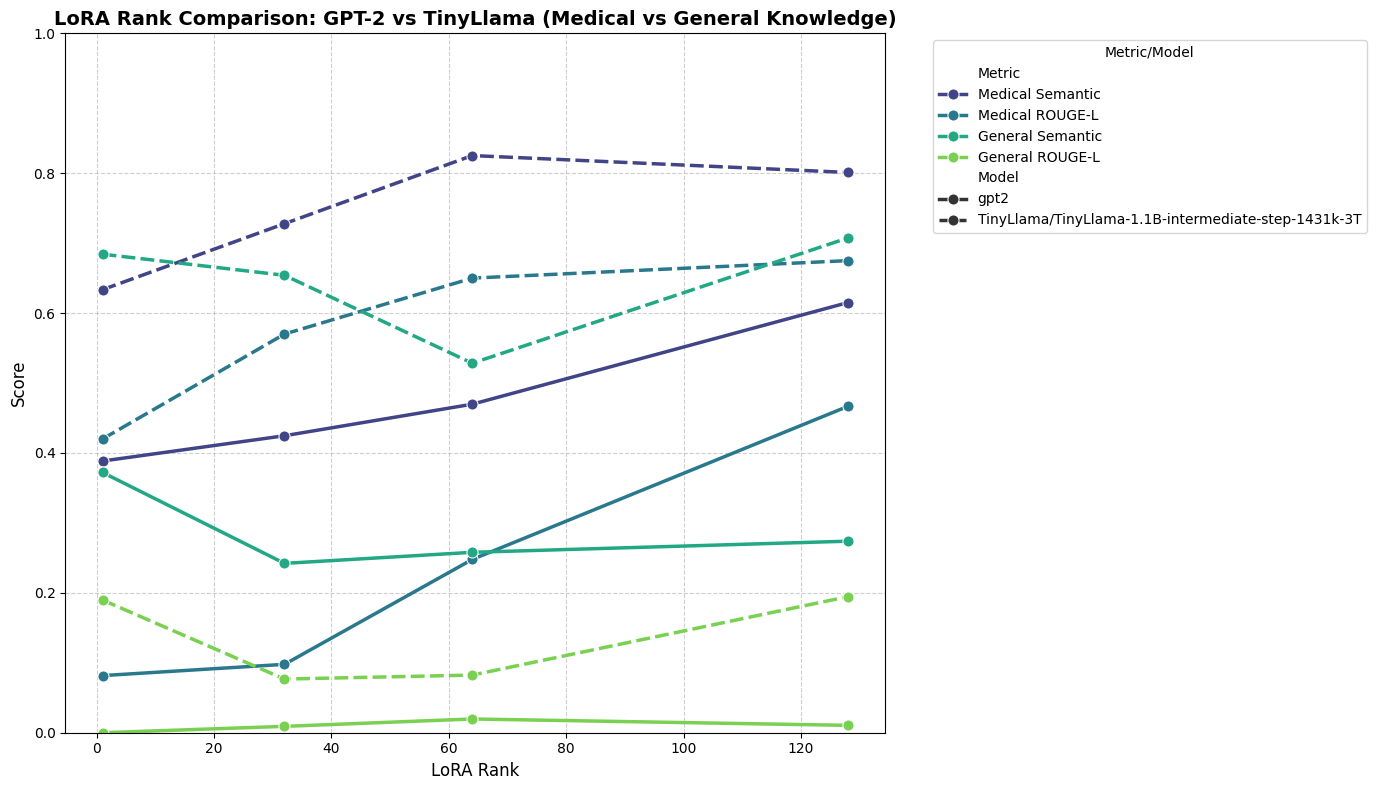


COMBINED LEARNING RATE RESULTS:
                                               Model  Learning Rate  \
0                                               gpt2        0.00001   
1                                               gpt2        0.00010   
2                                               gpt2        0.00030   
3                                               gpt2        0.00050   
4  TinyLlama/TinyLlama-1.1B-intermediate-step-143...        0.00001   
5  TinyLlama/TinyLlama-1.1B-intermediate-step-143...        0.00010   
6  TinyLlama/TinyLlama-1.1B-intermediate-step-143...        0.00030   
7  TinyLlama/TinyLlama-1.1B-intermediate-step-143...        0.00050   

   Medical Semantic  Medical ROUGE-L  General Semantic  General ROUGE-L  
0          0.342781         0.070000          0.382463         0.016667  
1          0.427535         0.116667          0.339585         0.039444  
2          0.469735         0.247778          0.257959         0.019643  
3          0.605204         0.4

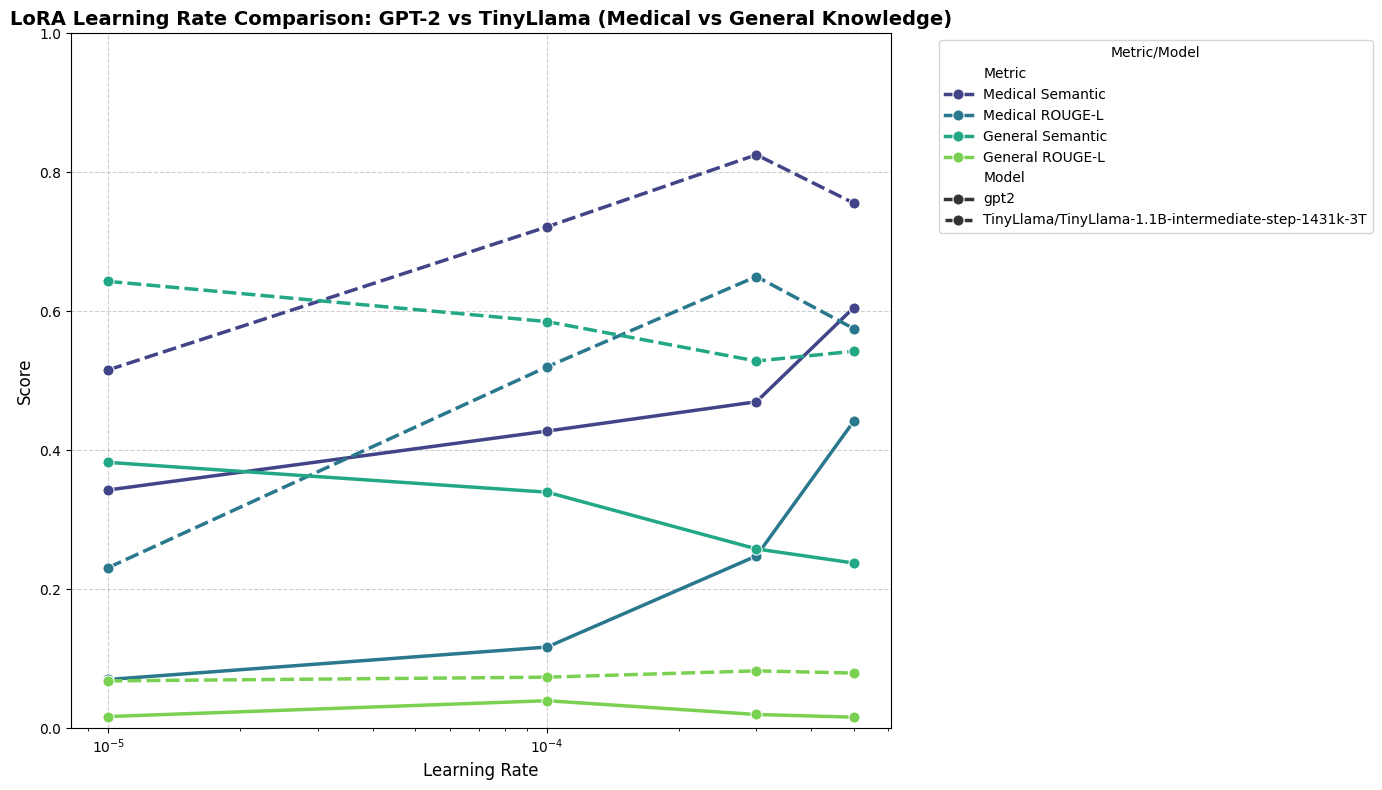


COMBINED EPOCH RESULTS:
                                               Model  Epochs  \
0                                               gpt2       1   
1                                               gpt2       2   
2                                               gpt2       3   
3                                               gpt2       5   
4  TinyLlama/TinyLlama-1.1B-intermediate-step-143...       1   
5  TinyLlama/TinyLlama-1.1B-intermediate-step-143...       2   
6  TinyLlama/TinyLlama-1.1B-intermediate-step-143...       3   
7  TinyLlama/TinyLlama-1.1B-intermediate-step-143...       5   

   Medical Semantic  Medical ROUGE-L  General Semantic  General ROUGE-L  
0          0.375377         0.077778          0.300940         0.006667  
1          0.420025         0.106111          0.249690         0.035833  
2          0.469735         0.247778          0.257959         0.019643  
3          0.637388         0.441667          0.216907         0.000000  
4          0.649088         

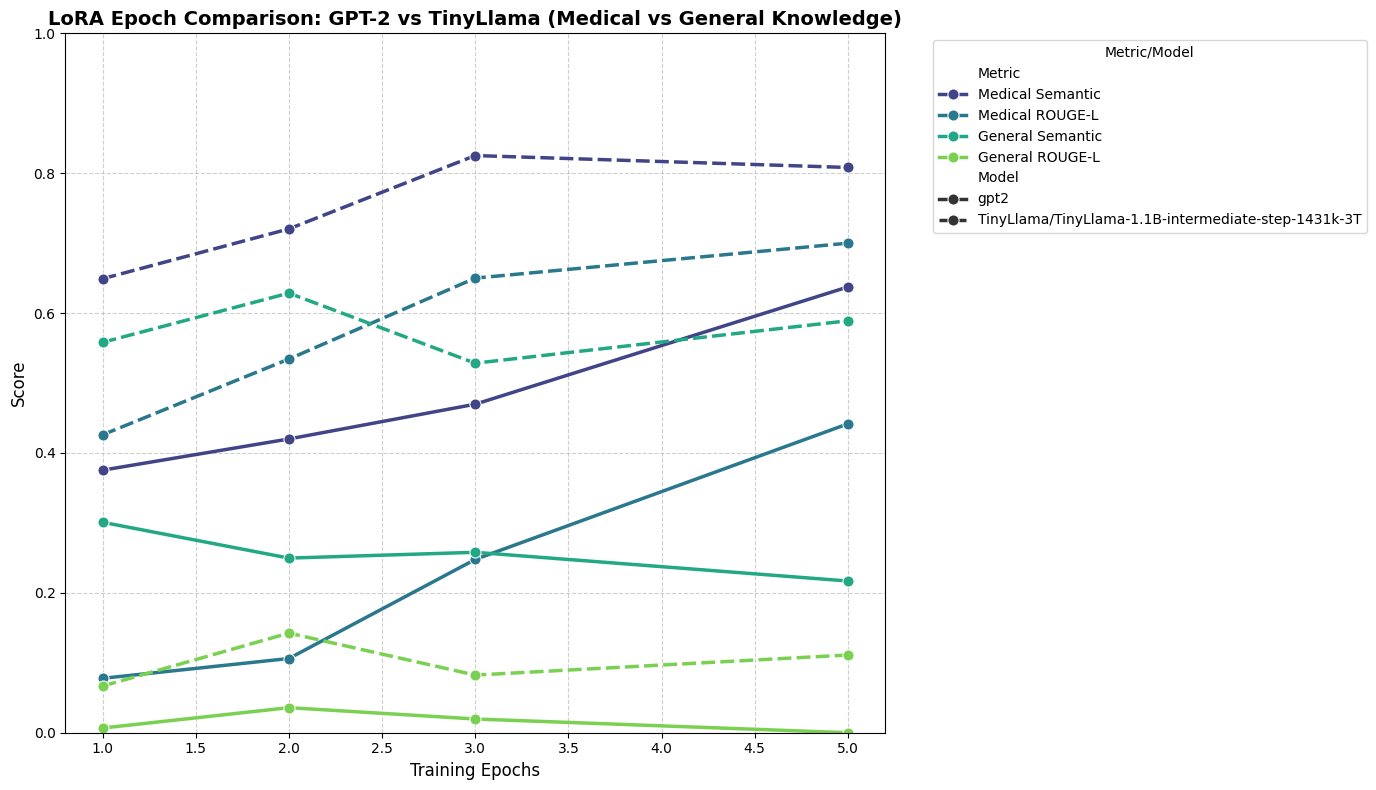


ALL EXPERIMENTS COMPLETED!


In [6]:
# =========================================================
# Execution
# =========================================================
if __name__ == "__main__":
    if not torch.cuda.is_available():
        raise RuntimeError('Select a GPU runtime before running the experiments.')
    if not Path(CSV_PATH).is_file():
        raise FileNotFoundError(f'Place the dataset at {CSV_PATH}, or update CSV_PATH in the setup cell.')
    all_baseline_results = []
    all_predictions = []
    models_to_test = ['gpt2', 'TinyLlama/TinyLlama-1.1B-intermediate-step-1431k-3T']

    all_rank_results = []
    all_lr_results = []
    all_epoch_results = []

    for model_name in models_to_test:
        print(f"\n{'='*80}")
        print(f"STARTING EXPERIMENTS FOR MODEL: {model_name}")
        print(f"{'='*80}\n")

        try:
            runner = LoRAExperiment(csv_path=CSV_PATH, model_name=model_name)
            baseline = runner.evaluate_baseline()
            all_baseline_results.append(baseline)
            print('Pretrained baseline:')
            print(baseline)

            # LoRA rank sweep
            print(f"\n{'#'*80}")
            print(f"RANK EXPERIMENT - {model_name.upper()}")
            print(f"{'#'*80}")
            df_rank = runner.train_and_evaluate(ranks=[1, 32, 64, 128])
            if df_rank is not None:
                all_rank_results.append(df_rank)
                print(f"\n{model_name} Rank Results:")
                print(df_rank)

            # Learning rate sweep
            print(f"\n{'#'*80}")
            print(f"LEARNING RATE EXPERIMENT - {model_name.upper()}")
            print(f"{'#'*80}")
            df_lr = runner.train_and_evaluate_lr(learning_rates=[1e-5, 1e-4, 3e-4, 5e-4])
            if df_lr is not None:
                all_lr_results.append(df_lr)
                print(f"\n{model_name} Learning Rate Results:")
                print(df_lr)

            # Training epoch sweep
            print(f"\n{'#'*80}")
            print(f"EPOCH EXPERIMENT - {model_name.upper()}")
            print(f"{'#'*80}")
            df_epoch = runner.train_and_evaluate_epochs(training_epochs=[1, 2, 3, 5])
            if df_epoch is not None:
                all_epoch_results.append(df_epoch)
                print(f"\n{model_name} Epoch Results:")
                print(df_epoch)

            all_predictions.extend(runner.predictions)
            pd.DataFrame(all_predictions).to_csv(RESULTS_DIR / 'predictions.csv', index=False)

        except Exception as e:
            print(f"Error running experiments for {model_name}: {e}")
            print("Skipping this model and continuing...")
            raise  # Do not silently report a failed experiment as completed.

    df_baseline = pd.concat(all_baseline_results, ignore_index=True)
    df_baseline.to_csv(RESULTS_DIR / 'baseline_results.csv', index=False)

    # Combining all the results and generating the plots

    # Rank Results
    if all_rank_results:
        df_rank_combined = pd.concat(all_rank_results, ignore_index=True)
        df_rank_combined.to_csv(RESULTS_DIR / 'rank_results.csv', index=False)
        print("\n" + "="*80)
        print("COMBINED RANK RESULTS:")
        print("="*80)
        print(df_rank_combined)

        plt.figure(figsize=(14, 8))
        plot_data = pd.melt(df_rank_combined, id_vars=['Model', 'Rank'], var_name='Metric', value_name='Score')

        # Creating separate plots for each metric or combine with model distinction
        sns.lineplot(data=plot_data, x='Rank', y='Score', hue='Metric', style='Model',
                    marker='o', palette='viridis', linewidth=2.5, markersize=8)
        plt.title('LoRA Rank Comparison: GPT-2 vs TinyLlama (Medical vs General Knowledge)', fontsize=14, fontweight='bold')
        plt.ylabel('Score', fontsize=12)
        plt.xlabel('LoRA Rank', fontsize=12)
        plt.ylim(0, 1.0)
        plt.grid(True, linestyle='--', alpha=0.6)
        plt.legend(title='Metric/Model', bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.tight_layout()
        plt.show()

    # Learning Rate Results
    if all_lr_results:
        df_lr_combined = pd.concat(all_lr_results, ignore_index=True)
        df_lr_combined.to_csv(RESULTS_DIR / 'lr_results.csv', index=False)
        print("\n" + "="*80)
        print("COMBINED LEARNING RATE RESULTS:")
        print("="*80)
        print(df_lr_combined)

        plt.figure(figsize=(14, 8))
        plot_data = pd.melt(df_lr_combined, id_vars=['Model', 'Learning Rate'], var_name='Metric', value_name='Score')

        sns.lineplot(data=plot_data, x='Learning Rate', y='Score', hue='Metric', style='Model',
                    marker='o', palette='viridis', linewidth=2.5, markersize=8)
        plt.title('LoRA Learning Rate Comparison: GPT-2 vs TinyLlama (Medical vs General Knowledge)',
                 fontsize=14, fontweight='bold')
        plt.ylabel('Score', fontsize=12)
        plt.xlabel('Learning Rate', fontsize=12)
        plt.xscale('log')
        plt.ylim(0, 1.0)
        plt.grid(True, linestyle='--', alpha=0.6)
        plt.legend(title='Metric/Model', bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.tight_layout()
        plt.show()

    # Epoch Results
    if all_epoch_results:
        df_epoch_combined = pd.concat(all_epoch_results, ignore_index=True)
        df_epoch_combined.to_csv(RESULTS_DIR / 'epoch_results.csv', index=False)
        print("\n" + "="*80)
        print("COMBINED EPOCH RESULTS:")
        print("="*80)
        print(df_epoch_combined)

        plt.figure(figsize=(14, 8))
        plot_data = pd.melt(df_epoch_combined, id_vars=['Model', 'Epochs'], var_name='Metric', value_name='Score')

        sns.lineplot(data=plot_data, x='Epochs', y='Score', hue='Metric', style='Model',
                    marker='o', palette='viridis', linewidth=2.5, markersize=8)
        plt.title('LoRA Epoch Comparison: GPT-2 vs TinyLlama (Medical vs General Knowledge)',
                 fontsize=14, fontweight='bold')
        plt.ylabel('Score', fontsize=12)
        plt.xlabel('Training Epochs', fontsize=12)
        plt.ylim(0, 1.0)
        plt.grid(True, linestyle='--', alpha=0.6)
        plt.legend(title='Metric/Model', bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.tight_layout()
        plt.show()

    print("\n" + "="*80)
    print("ALL EXPERIMENTS COMPLETED!")
    print("="*80)
    # Positive General Semantic Drop indicates a decline relative to the same model's baseline.
    for name, frames in [('rank', all_rank_results), ('lr', all_lr_results), ('epoch', all_epoch_results)]:
        frame = pd.concat(frames, ignore_index=True)
        comparison = frame.merge(df_baseline, on='Model', suffixes=('', ' Baseline'))
        comparison['General Semantic Drop'] = comparison['General Semantic Baseline'] - comparison['General Semantic']
        comparison['General ROUGE-L Drop'] = comparison['General ROUGE-L Baseline'] - comparison['General ROUGE-L']
        comparison.to_csv(RESULTS_DIR / f'{name}_baseline_comparison.csv', index=False)
